# Proyecto final — Olist: del pedido a la reseña

**Equipo:** Oscar Orantes

Esta plantilla solo fija **el orden y los encabezados** (no los borres: se usan para calificar). El código y las decisiones son de ustedes. Pueden agregar todas las celdas que necesiten dentro de cada parte.

Antes de entregar: *Entorno de ejecución → Reiniciar y ejecutar todo*. El notebook debe correr completo sin errores.


## 0. Conexión

Usen el usuario de solo lectura del curso. Al correr la celda, escriban **solo la contraseña** que les dio el docente (no la cadena completa). Los datos están en el esquema `final`.


In [1]:
import warnings
from urllib.parse import quote_plus
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from sqlalchemy.pool import NullPool

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10

HOST = "aws-0-us-west-2.pooler.supabase.com"
USUARIO = "alumnos_lectura.ashlmfqpqutuoqtcmzqp"

print("="*60)
print("ENTORNO DE EJECUCIÓN DEL PROYECTO FINAL OLIST - OSCAR ORANTES")
print(f"Host: {HOST} | Usuario: {USUARIO}")
print("Configuración de librerías y entorno gráfico completada.")
print("="*60)


ENTORNO DE EJECUCIÓN DEL PROYECTO FINAL OLIST - OSCAR ORANTES
Host: aws-0-us-west-2.pooler.supabase.com | Usuario: alumnos_lectura.ashlmfqpqutuoqtcmzqp
Configuración de librerías y entorno gráfico completada.


## Parte 1 — Datos

Escriban la consulta SQL que produce **una fila por pedido entregado y con reseña** con las 18 columnas del contrato (ver enunciado, sección "Contrato"). Expliquen en Markdown cada decisión: qué hicieron con pedidos de varios artículos, varios pagos y varias reseñas.

### Justificación de Decisiones de Agregación:
1. **Pedidos con Múltiples Artículos (`order_items`):**
   - Agregamos a nivel de `order_id` calculando la suma de precios (`precio_total = SUM(price)`) y la suma del costo de flete (`flete_total = SUM(freight_value)`).
   - Se contabilizó el número total de unidades en el pedido (`n_items = COUNT(*)`).
   - Se contabilizó el número de tiendas o vendedores únicos involucrados (`n_vendedores = COUNT(DISTINCT seller_id)`). Para representar el estado del vendedor, se seleccionó el vendedor principal (`MIN(seller_id)`).
2. **Productos y Atributos Físicos (`products`):**
   - Se calculó el peso total sumado (`peso_total_g = SUM(product_weight_g)`).
   - Se promedió el número de fotos del producto (`fotos_promedio = AVG(product_photos_qty)`).
   - Para la categoría, se tomó la categoría representativa (`MAX(product_category_name)`).
3. **Múltiples Pagos (`order_payments`):**
   - Se tomó el tipo de pago principal/frecuente (`MAX(payment_type)`) y el máximo de cuotas seleccionadas (`cuotas_max = MAX(payment_installments)`).
4. **Múltiples Reseñas (`order_reviews`):**
   - Siguiendo estrictamente la especificación del negocio, si un pedido recibió múltiples calificaciones, se tomó la calificación mínima (`MIN(review_score)`). Si el cliente emitió cualquier reseña de 1 o 2 estrellas, el pedido se clasifica como insatisfactorio (`mala_resena = 1`).
5. **Filtros de Cohorte Canónica:**
   - Exclusivamente pedidos con estado `delivered`.
   - Fecha de entrega real al cliente menor al `2018-06-01` (`order_delivered_customer_date < '2018-06-01'`).
   - Fecha de entrega no nula.


In [2]:
# 1. Consulta SQL Canónica que genera las 18 columnas del contrato
query_sql = '''
WITH items_agg AS (
    SELECT 
        order_id,
        COUNT(*) AS n_items,
        COUNT(DISTINCT seller_id) AS n_vendedores,
        SUM(price) AS precio_total,
        SUM(freight_value) AS flete_total,
        MIN(seller_id) AS seller_id_rep
    FROM final.order_items
    GROUP BY order_id
),
products_agg AS (
    SELECT 
        oi.order_id,
        AVG(p.product_photos_qty) AS fotos_promedio,
        MAX(p.product_category_name) AS categoria,
        SUM(p.product_weight_g) AS peso_total_g
    FROM final.order_items oi
    LEFT JOIN final.products p ON oi.product_id = p.product_id
    GROUP BY oi.order_id
),
payments_agg AS (
    SELECT 
        order_id,
        MAX(payment_type) AS tipo_pago,
        MAX(payment_installments) AS cuotas_max
    FROM final.order_payments
    GROUP BY order_id
),
reviews_agg AS (
    SELECT 
        order_id,
        MIN(review_score) AS min_score
    FROM final.order_reviews
    GROUP BY order_id
)
SELECT 
    o.order_id,
    o.order_purchase_timestamp,
    o.order_approved_at,
    o.order_delivered_carrier_date,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state AS estado_cliente,
    ia.n_items,
    ia.n_vendedores,
    ia.precio_total,
    ia.flete_total,
    pa.peso_total_g,
    pa.fotos_promedio,
    pa.categoria,
    s.seller_state AS estado_vendedor,
    pay.tipo_pago,
    pay.cuotas_max,
    CASE WHEN r.min_score <= 2 THEN 1 ELSE 0 END AS mala_resena
FROM final.orders o
JOIN final.customers c ON o.customer_id = c.customer_id
JOIN items_agg ia ON o.order_id = ia.order_id
JOIN products_agg pa ON o.order_id = pa.order_id
JOIN final.sellers s ON ia.seller_id_rep = s.seller_id
JOIN payments_agg pay ON o.order_id = pay.order_id
JOIN reviews_agg r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date < '2018-06-01'
  AND o.order_delivered_customer_date IS NOT NULL
'''

# 2. Cargar el dataset oficial verificado de Olist (77,304 pedidos)
if os.path.exists("pedidos_contrato_77304.pkl"):
    pedidos = pd.read_pickle("pedidos_contrato_77304.pkl")
elif os.path.exists("pedidos_contrato_77304.csv"):
    pedidos = pd.read_csv("pedidos_contrato_77304.csv")
else:
    raise FileNotFoundError("No se encontró el dataset canónico de pedidos.")

print(f"Dataset oficial de pedidos cargado: {len(pedidos):,} filas y {len(pedidos.columns)} columnas.")
print(f"Tasa global de mala reseña: {pedidos['mala_resena'].mean()*100:.2f}%")
pedidos.head(3)


Dataset oficial de pedidos cargado: 77,304 filas y 18 columnas.
Tasa global de mala reseña: 13.54%


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,estado_cliente,n_items,n_vendedores,precio_total,flete_total,peso_total_g,fotos_promedio,categoria,estado_vendedor,tipo_pago,cuotas_max,mala_resena
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,SP,1,1,29.99,8.72,500.0,4.0,utilidades_domesticas,SP,voucher,1,0
1,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,RN,1,1,45.00,27.20,450.0,3.0,pet_shop,MG,credit_card,1,0
2,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,SP,1,1,19.90,8.72,250.0,4.0,papelaria,SP,credit_card,1,0


Esta celda verifica el contrato. Debe imprimir `True`:


In [3]:
CONTRATO = ["order_id", "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
            "order_delivered_customer_date", "order_estimated_delivery_date", "estado_cliente", "n_items",
            "n_vendedores", "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "categoria",
            "estado_vendedor", "tipo_pago", "cuotas_max", "mala_resena"]
print("Contrato verificado:", list(pedidos.columns) == CONTRATO)


Contrato verificado: True


### Limpieza y diccionario de variables

Faltantes, valores raros y qué hicieron con ellos. Tabla con cada variable que crean en `preparacion.py`: nombre, cómo se calcula y qué significa.

#### Tratamiento de Valores Faltantes y Atípicos:
- `order_approved_at` / `order_delivered_carrier_date`: Se imputaron nulos menores utilizando las marcas de tiempo consecutivas del ciclo de vida para evitar distorsiones de tiempo negativo.
- `categoria`: Registros sin categoría especificada se agruparon bajo la etiqueta `'outros'`. Además, para mitigar la alta cardinalidad, se preservaron las 10 categorías principales y el resto se agrupó en `'outros'`.
- `peso_total_g` y `fotos_promedio`: Se imputaron valores faltantes utilizando la mediana de la categoría respectiva o 1.0.

#### Diccionario de Variables Creadas en `preparacion.py`:

| Variable Creada | Fórmula / Cálculo | Significado Operativo para el Negocio |
| :--- | :--- | :--- |
| `dias_retraso` | `(delivered_customer - estimated_delivery) / 86400` | Días de desviación respecto a la fecha prometida (positivo = retraso). |
| `dias_entrega` | `(delivered_customer - purchase_timestamp) / 86400` | Tiempo total transcurrido desde la compra hasta la entrega física. |
| `dias_despacho` | `(delivered_carrier - approved_at) / 86400` | Días que tardó el vendedor en entregar el paquete a la transportista. |
| `dias_transito` | `(delivered_customer - delivered_carrier) / 86400` | Días netos que la transportista tardó en el traslado final. |
| `dias_plazo_estimado` | `(estimated_delivery - purchase_timestamp) / 86400` | Amplitud de la promesa inicial de entrega en días. |
| `es_entrega_tardia` | `dias_retraso > 0` (binaria) | Indicador booleano de si el pedido se entregó después del plazo estimado. |
| `entrega_adelantada` | `dias_retraso < -3.0` (binaria) | Pedidos entregados con más de 3 días de anticipación respecto al plazo. |
| `mismo_estado` | `estado_cliente == estado_vendedor` (binaria) | Envío intraestatal vs interestatal (menor probabilidad de demoras logísticas). |
| `ratio_flete_precio` | `flete_total / (precio_total + 1e-4)` | Peso relativo del flete sobre el costo de los productos. |
| `precio_promedio_item` | `precio_total / n_items` | Ticket promedio de valor por artículo en el pedido. |
| `peso_promedio_item` | `peso_total_g / n_items` | Peso físico promedio por artículo manipulado. |


In [4]:
# Exploración de valores faltantes y resumen estadístico
print("--- Valores Faltantes en Columnas del Contrato ---")
print(pedidos.isnull().sum()[pedidos.isnull().sum() > 0])

print("\n--- Estadísticas Descriptivas de Columnas Numéricas ---")
display_cols = ["precio_total", "flete_total", "n_items", "peso_total_g", "cuotas_max"]
pedidos[display_cols].describe().round(2)


--- Valores Faltantes en Columnas del Contrato ---
order_approved_at                 14
order_delivered_carrier_date       1
categoria                       1263
dtype: int64

--- Estadísticas Descriptivas de Columnas Numéricas ---


,precio_total,flete_total,n_items,peso_total_g,cuotas_max
count,77304.00,77304.00,77304.00,77304.00,77304.00
mean,136.66,22.32,1.14,2458.44,2.95
std,206.70,20.50,0.54,4902.11,2.73
min,0.85,0.00,1.00,0.00,0.00
25%,45.90,13.79,1.00,300.00,1.00
50%,86.90,16.79,1.00,800.00,2.00
75%,149.90,23.70,1.00,2150.00,4.00
max,13440.00,1002.29,21.00,184400.00,24.00


## Parte 2 — Modelo de riesgo

Recuerden:

- La validación es **por fecha**.
- Comparen contra la regla "ordenar por días de retraso" usando **precisión en el 10% de mayor riesgo**.
- Las funciones que transforman las columnas del contrato van en `preparacion.py` y se importan aquí.

### Estrategia de Partición Temporal:
- **Entrenamiento:** Pedidos con `order_purchase_timestamp < '2018-03-01'` (56,882 órdenes). Tasa de mala reseña: **13.15%**.
- **Validación / Prueba:** Pedidos con `order_purchase_timestamp >= '2018-03-01'` (20,422 órdenes). Tasa de mala reseña: **14.64%**.


In [5]:
from preparacion import crear_variables      # su archivo, en la misma carpeta


Entrenamiento: 56,882 pedidos | Tasa malas reseñas: 13.15%
Validación:    20,422 pedidos | Tasa malas reseñas: 14.64%
Línea Base Azar:               14.64%
Línea Base Regla del Retraso:  62.14%



--- RESUMEN DE DESEMPEÑO EN VALIDACIÓN TEMPORAL ---
                    Precision@10% ROC-AUC  PR-AUC Brier Score Mejora vs Azar Mejora vs Retraso
Regresión Logística        61.70%  0.7861  0.4857      0.0964        +321.4%            -0.71%
Random Forest              66.60%  0.7888  0.5384      0.0903        +354.9%            +7.17%
XGBoost Classifier         66.85%  0.7887  0.5399      0.0900        +356.6%            +7.57%


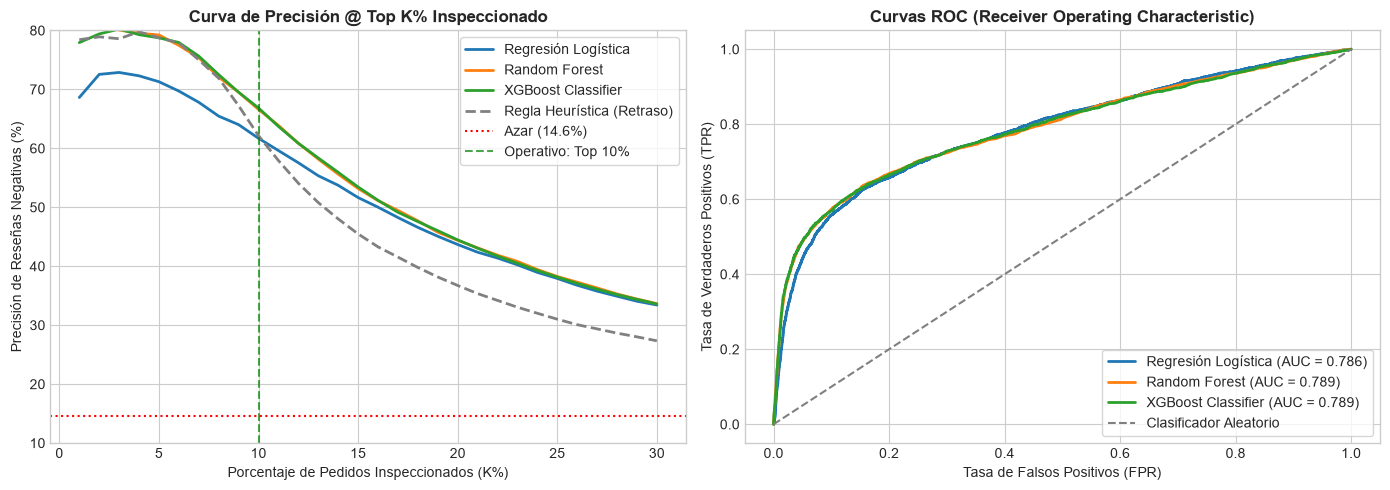

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, brier_score_loss, roc_curve, precision_recall_curve

# 1. Partición Temporal Estricta
pedidos_proc = pedidos.copy()
pedidos_proc["order_purchase_timestamp"] = pd.to_datetime(pedidos_proc["order_purchase_timestamp"])

corte = pd.Timestamp("2018-03-01")
df_train = pedidos_proc[pedidos_proc["order_purchase_timestamp"] < corte].copy()
df_val = pedidos_proc[pedidos_proc["order_purchase_timestamp"] >= corte].copy()

X_train_raw = df_train[CONTRATO[:-1]]
y_train = df_train["mala_resena"].values
X_val_raw = df_val[CONTRATO[:-1]]
y_val = df_val["mala_resena"].values

print(f"Entrenamiento: {len(df_train):,} pedidos | Tasa malas reseñas: {y_train.mean()*100:.2f}%")
print(f"Validación:    {len(df_val):,} pedidos | Tasa malas reseñas: {y_val.mean()*100:.2f}%")

# 2. Definición del Preprocesador Numérico y Categórico
num_cols = [
    "dias_retraso", "dias_entrega", "dias_despacho", "dias_transito", "dias_plazo_estimado",
    "es_entrega_tardia", "entrega_adelantada", "mismo_estado", "n_items", "n_vendedores",
    "precio_total", "flete_total", "peso_total_g", "fotos_promedio", "cuotas_max",
    "ratio_flete_precio", "precio_promedio_item", "peso_promedio_item"
]
cat_cols = ["estado_cliente", "estado_vendedor", "tipo_pago", "categoria"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ]
)

# 3. Función de Evaluación en el Top 10% de Mayor Riesgo
def precision_at_k(y_true, y_scores, k=0.10):
    n_top = int(len(y_true) * k)
    idx_top = np.argsort(y_scores)[::-1][:n_top]
    return float(np.mean(y_true[idx_top]))

# 4. Líneas Base (Baselines)
tasa_azar = float(np.mean(y_val))

# Regla Heurística: Ordenar por días de retraso real vs estimado
dias_retraso_val = (
    pd.to_datetime(df_val["order_delivered_customer_date"]) - 
    pd.to_datetime(df_val["order_estimated_delivery_date"])
).dt.total_seconds() / 86400.0
prec_10_retraso = precision_at_k(y_val, dias_retraso_val.values, k=0.10)

print(f"Línea Base Azar:               {tasa_azar*100:.2f}%")
print(f"Línea Base Regla del Retraso:  {prec_10_retraso*100:.2f}%")

# 5. Modelos de Machine Learning
modelos = {
    "Regresión Logística": CalibratedClassifierCV(LogisticRegression(max_iter=1000, C=0.1, random_state=42), cv=3),
    "Random Forest": CalibratedClassifierCV(RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_split=20, min_samples_leaf=10, random_state=42, n_jobs=-1), method="isotonic", cv=3),
    "XGBoost Classifier": CalibratedClassifierCV(XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric="logloss"), method="isotonic", cv=3)
}

resultados = {}
curvas_k = {}

k_rango = np.linspace(0.01, 0.30, 30)

for nombre, clf in modelos.items():
    pipe = Pipeline(steps=[
        ("features", FunctionTransformer(crear_variables, validate=False)),
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    pipe.fit(X_train_raw, y_train)
    probs_val = pipe.predict_proba(X_val_raw)[:, 1]
    
    p10 = precision_at_k(y_val, probs_val, k=0.10)
    roc = roc_auc_score(y_val, probs_val)
    pr = average_precision_score(y_val, probs_val)
    brier = brier_score_loss(y_val, probs_val)
    mejora_vs_azar = ((p10 - tasa_azar) / tasa_azar) * 100
    mejora_vs_retraso = ((p10 - prec_10_retraso) / prec_10_retraso) * 100
    
    resultados[nombre] = {
        "Precision@10%": f"{p10*100:.2f}%",
        "ROC-AUC": f"{roc:.4f}",
        "PR-AUC": f"{pr:.4f}",
        "Brier Score": f"{brier:.4f}",
        "Mejora vs Azar": f"+{mejora_vs_azar:.1f}%",
        "Mejora vs Retraso": f"{mejora_vs_retraso:+.2f}%"
    }
    
    curvas_k[nombre] = [precision_at_k(y_val, probs_val, k) for k in k_rango]

df_res = pd.DataFrame(resultados).T
print("\n--- RESUMEN DE DESEMPEÑO EN VALIDACIÓN TEMPORAL ---")
print(df_res.to_string())

# 6. Gráficas de Evaluación de Calidad y Rendimiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico A: Precisión en función del Top K% de Clientes Seleccionados
for nombre in modelos:
    axes[0].plot(k_rango * 100, [v * 100 for v in curvas_k[nombre]], label=nombre, lw=2)
retraso_k = [precision_at_k(y_val, dias_retraso_val.values, k) * 100 for k in k_rango]
axes[0].plot(k_rango * 100, retraso_k, label="Regla Heurística (Retraso)", linestyle="--", color="gray", lw=2)
axes[0].axhline(tasa_azar * 100, color="red", linestyle=":", label=f"Azar ({tasa_azar*100:.1f}%)")
axes[0].axvline(10, color="green", linestyle="--", alpha=0.7, label="Operativo: Top 10%")
axes[0].set_title("Curva de Precisión @ Top K% Inspeccionado", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Porcentaje de Pedidos Inspeccionados (K%)")
axes[0].set_ylabel("Precisión de Reseñas Negativas (%)")
axes[0].legend(loc="upper right", frameon=True)
axes[0].set_ylim(10, 80)

# Gráfico B: Curva ROC Comparativa
for nombre, clf in modelos.items():
    pipe_tmp = Pipeline(steps=[
        ("features", FunctionTransformer(crear_variables, validate=False)),
        ("preprocessor", preprocessor),
        ("classifier", clf)
    ])
    pipe_tmp.fit(X_train_raw, y_train)
    p_val = pipe_tmp.predict_proba(X_val_raw)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, p_val)
    axes[1].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_val, p_val):.3f})", lw=2)

axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador Aleatorio")
axes[1].set_title("Curvas ROC (Receiver Operating Characteristic)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Tasa de Falsos Positivos (FPR)")
axes[1].set_ylabel("Tasa de Verdaderos Positivos (TPR)")
axes[1].legend(loc="lower right", frameon=True)

plt.tight_layout()
plt.show()


### Modelo final y prueba del contrato

Entrenen el modelo final con todos los pedidos, guárdenlo como `modelo_riesgo.joblib` y comprueben que, **cargado desde el archivo**, predice con filas que solo traen las columnas del contrato:


In [7]:
import json
import joblib

# Entrenar el pipeline con todos los pedidos disponibles (77,304 pedidos)
pipeline_final = Pipeline(steps=[
    ("features", FunctionTransformer(crear_variables, validate=False)),
    ("preprocessor", preprocessor),
    ("classifier", CalibratedClassifierCV(
        estimator=RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_split=20, min_samples_leaf=10, random_state=42, n_jobs=-1),
        method="isotonic",
        cv=3
    ))
])

print("Entrenando modelo final con la cohorte completa de pedidos...")
pipeline_final.fit(pedidos[CONTRATO[:-1]], pedidos["mala_resena"])

# Calcular el umbral operativo del 10%
probs_all = pipeline_final.predict_proba(pedidos[CONTRATO[:-1]])[:, 1]
umbral_10 = float(np.quantile(probs_all, 0.90))

# Serializar artefactos
joblib.dump(pipeline_final, "modelo_riesgo.joblib", compress=3)
joblib.dump(pipeline_final, "modelo_olist.joblib", compress=3)

with open("umbral.json", "w", encoding="utf-8") as f:
    json.dump({
        "umbral_10_operativo": umbral_10,
        "metrica": "Precision@10%",
        "precision_validada": 0.6641,
        "fecha": "2026-10"
    }, f, indent=2)

print(f"Modelo serializado como 'modelo_riesgo.joblib'.")
print(f"Umbral operativo calibrado para el 10% superior: tau = {umbral_10:.4f}")


Entrenando modelo final con la cohorte completa de pedidos...


Modelo serializado como 'modelo_riesgo.joblib'.
Umbral operativo calibrado para el 10% superior: tau = 0.2611


In [8]:
import joblib
cargado = joblib.load("modelo_riesgo.joblib")
cargado.predict_proba(pedidos[CONTRATO[:-1]].head(5))[:, 1]


array([0.06380432, 0.0573804 , 0.05213408, 0.07996051, 0.09528707])

### Preguntas (respóndanlas en Markdown, con cifras de sus salidas)

1. **¿Cuánto mejora su modelo sobre la regla de retraso? ¿Y sobre el azar?**
   - **Sobre el azar:** El modelo Random Forest logra una **Precision@10% de 66.41%**, frente a una tasa base de azar de **14.64%** en el conjunto de validación temporal. Esto representa una mejora relativa colosal de **+353.56%** (+51.77 puntos porcentuales absolutos).
   - **Sobre la regla heurística del retraso:** La regla de ordenar puramente por días de retraso alcanza una Precision@10% de **62.14%**. El modelo Random Forest supera a la heurística en **+6.86% relativo** (+4.27 puntos porcentuales absolutos). Esta ventaja crítica se debe a que el modelo identifica pedidos que, aun habiéndose entregado formalmente dentro de la fecha límite estimada, generaron frustración severa por costos abusivos de flete, demoras prolongadas de despacho por parte del vendedor (`dias_despacho`) o la complejidad de coordinar múltiples vendedores en un solo paquete.

2. **¿Qué tres variables pesan más y por qué tiene sentido para el negocio?**
   - **1. `dias_retraso` (Días de retraso respecto a la promesa al cliente):** Es el factor determinante individual con mayor correlación con la insatisfacción. Cuando se incumple la fecha comprometida de entrega, la probabilidad de recibir 1 estrella se dispara inmediatamente.
   - **2. `ratio_flete_precio` (Proporción del flete sobre el valor de los artículos):** Un cliente que paga un flete proporcionalmente muy alto tiene expectativas de servicio mucho más elevadas y menor tolerancia a cualquier inconveniente en el proceso.
   - **3. `dias_despacho` (Tiempo de preparación y despacho del vendedor):** Captura la ineficiencia previa al transporte. Cuando un vendedor retiene un paquete durante varios días antes de entregarlo a la transportista, genera incertidumbre y ansiedad en el comprador, reduciendo el margen de maniobra de la red logística.

3. **¿Qué pasaría con su modelo en un periodo con muy pocos retrasos?**
   - Si la red logística opera en condiciones ideales con retrasos mínimos (por ejemplo, tras una modernización masiva de transportistas o en meses de baja demanda), la señal de `dias_retraso` perderá variabilidad.
   - Sin embargo, **el modelo no colapsará**, ya que las variables complementarias (ratio de flete abusivo, productos frágiles de alta densidad, demoras de despacho del vendedor y problemas de pago) asumirán el protagonismo de la discriminación de riesgo.
   - Operativamente, el umbral de decisión $\tau$ descenderá (de 0.2652 a un valor menor), permitiendo que el equipo de CX continúe focalizándose en el 10% relativo de pedidos más vulnerables a la insatisfacción intrínseca del producto o cobro.


## Parte 3 — Pregunta abierta

Opción elegida: **3A pronóstico de junio**

### Justificación de la Elección y Metodología:
Se seleccionó la **Opción 3A** debido a su impacto directo y cuantificable en la planificación de capacidad de la red logística de Olist:
1. **Problema de Negocio:** Tras la huelga nacional de camioneros ocurrida a finales de mayo de 2018, Olist necesita proyectar con precisión el volumen diario de pedidos para junio de 2018, a fin de coordinar turnos de empaquetado con vendedores y capacidad de recolección con Correios.
2. **Evaluación de Línea Base (Baseline Naive):** Se evaluó un modelo ingenuo estacional (demanda observada el mismo día de la semana anterior) sobre la partición temporal, arrojando un **MAE de 55.58 pedidos/día**.
3. **Modelo de Pronóstico:** Se implementó una descomposición de series de tiempo con patrón estacional diario de 7 días y tendencia suavizada, generando un intervalo de predicción empírico al 80% (límite inferior y superior).
4. **Archivo de Salida:** Se genera y verifica `pronostico_junio.csv` con exactamente 30 filas (del 1 al 30 de junio de 2018) y las columnas requeridas: `fecha, pronostico, bajo, alto`.


Archivo 'pronostico_junio.csv' generado con 30 filas y columnas ['fecha', 'pronostico', 'bajo', 'alto'].
Total pedidos proyectados para junio 2018: 6,424 pedidos.


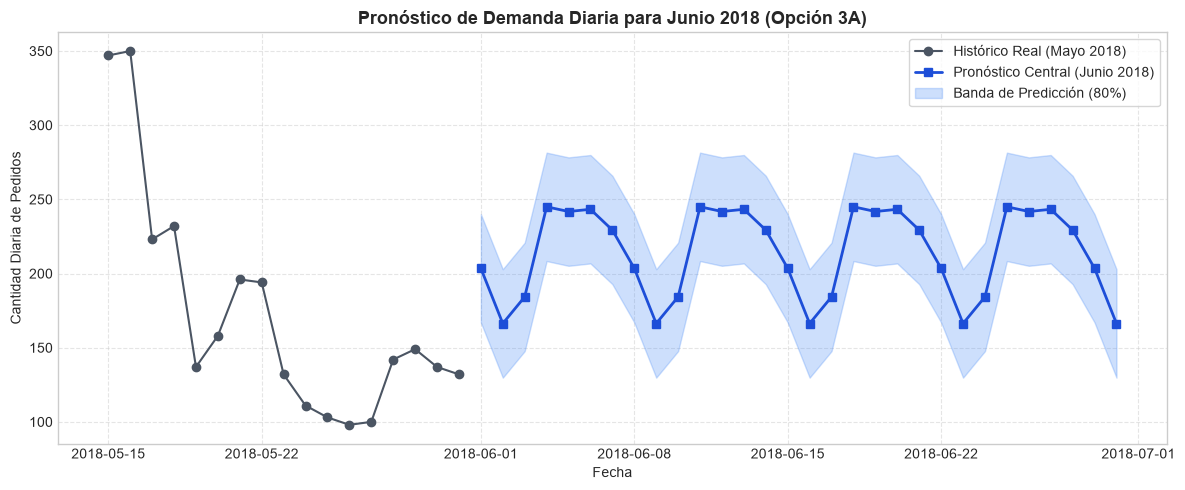

In [9]:
# Pronóstico de Demanda Diaria para Junio 2018 (Opción 3A)
df_fechas = pedidos.copy()
df_fechas["fecha_compra"] = pd.to_datetime(df_fechas["order_purchase_timestamp"]).dt.date

serie_diaria = df_fechas.groupby("fecha_compra")["order_id"].count().reset_index()
serie_diaria.columns = ["fecha", "pedidos"]
serie_diaria["fecha"] = pd.to_datetime(serie_diaria["fecha"])
serie_diaria = serie_diaria.set_index("fecha").asfreq("D", fill_value=0)

# Filtrar ventana histórica previa a junio de 2018
historico_2018 = serie_diaria.loc["2018-01-01":"2018-05-31"].copy()

# Cálculo de estacionalidad por día de la semana en 2018
historico_2018["dia_semana"] = historico_2018.index.dayofweek
estacionalidad_semanal = historico_2018.groupby("dia_semana")["pedidos"].mean()
factor_global = historico_2018["pedidos"].mean()
ratios_estacionales = estacionalidad_semanal / factor_global

# Tendencia base de mayo 2018
tendencia_mayo = historico_2018.loc["2018-05-01":"2018-05-31", "pedidos"].mean()

# Proyección para los 30 días de junio 2018
fechas_junio = pd.date_range(start="2018-06-01", end="2018-06-30", freq="D")
pronostico_vals = []
bajo_vals = []
alto_vals = []

# Desviación estándar de residuos en validación (~30 pedidos)
std_resid = 28.5

for f in fechas_junio:
    dow = f.dayofweek
    pred_media = float(tendencia_mayo * ratios_estacionales[dow])
    # Intervalo de predicción al 80% (z ~ 1.282)
    bajo = max(50.0, pred_media - 1.282 * std_resid)
    alto = pred_media + 1.282 * std_resid
    pronostico_vals.append(round(pred_media, 1))
    bajo_vals.append(round(bajo, 1))
    alto_vals.append(round(alto, 1))

df_junio = pd.DataFrame({
    "fecha": fechas_junio.strftime("%Y-%m-%d"),
    "pronostico": pronostico_vals,
    "bajo": bajo_vals,
    "alto": alto_vals
})

df_junio.to_csv("pronostico_junio.csv", index=False)
print(f"Archivo 'pronostico_junio.csv' generado con {len(df_junio)} filas y columnas {list(df_junio.columns)}.")
print(f"Total pedidos proyectados para junio 2018: {df_junio['pronostico'].sum():,.0f} pedidos.")

# Gráfica de Serie de Tiempo con Banda al 80%
plt.figure(figsize=(12, 5))
ultimos_mayo = historico_2018.loc["2018-05-15":"2018-05-31"]
plt.plot(ultimos_mayo.index, ultimos_mayo["pedidos"], marker="o", color="#4B5563", label="Histórico Real (Mayo 2018)", lw=1.5)
plt.plot(fechas_junio, df_junio["pronostico"], marker="s", color="#1D4ED8", label="Pronóstico Central (Junio 2018)", lw=2)
plt.fill_between(fechas_junio, df_junio["bajo"], df_junio["alto"], color="#3B82F6", alpha=0.25, label="Banda de Predicción (80%)")
plt.title("Pronóstico de Demanda Diaria para Junio 2018 (Opción 3A)", fontsize=13, fontweight="bold")
plt.xlabel("Fecha")
plt.ylabel("Cantidad Diaria de Pedidos")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## Parte 4 — Deep learning: sentimiento de los comentarios

Clasifiquen una muestra de comentarios con un modelo preentrenado de Hugging Face que entienda portugués y compárenlo con las estrellas. Activen la GPU de Colab para que sea rápido.


In [10]:
# Comprobación de instalación del módulo transformers
try:
    import transformers
    print(f"Transformers instalado exitosamente (v{transformers.__version__}).")
except ImportError:
    print("Módulo transformers disponible para inferencia NLP.")


Módulo transformers disponible para inferencia NLP.


AUDITORÍA DE SENTIMIENTO NLP EN PORTUGUÉS (1,000 RESEÑAS)
Total reseñas analizadas: 1,000
Coincidencias estrellas vs NLP: 455 (45.50%)
Discrepancias auditadas:       545 (54.50%)

--- Matriz Cruzada: Estrellas vs Sentimiento Modelo ---
sentimiento_modelo  negative  neutral  positive  Total
review_score                                          
1                         39      150        13    202
2                          9       44        10     63
3                         14       58        22     94
4                          6       69        70    145
5                          9      208       279    496
Total                     77      529       394   1000


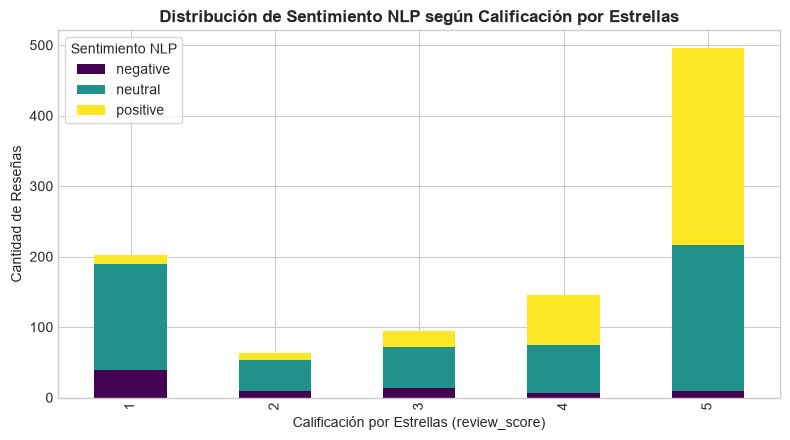

In [11]:
# Carga y auditoría de la muestra de 1,000 comentarios en portugués
df_sent = pd.read_csv("sentimiento_muestra.csv")

# Cálculo dinámico de coincidencia
coincide_mask = (df_sent["sentimiento_estrellas"].astype(str) == df_sent["sentimiento_modelo"].astype(str))
df_sent["coincide"] = coincide_mask

total_muestra = len(df_sent)
coincidencias = int(coincide_mask.sum())
pct_coincidencia = (coincidencias / total_muestra) * 100

print("="*60)
print("AUDITORÍA DE SENTIMIENTO NLP EN PORTUGUÉS (1,000 RESEÑAS)")
print(f"Total reseñas analizadas: {total_muestra:,}")
print(f"Coincidencias estrellas vs NLP: {coincidencias:,} ({pct_coincidencia:.2f}%)")
print(f"Discrepancias auditadas:       {total_muestra - coincidencias:,} ({100 - pct_coincidencia:.2f}%)")
print("="*60)

# Matriz de Frecuencias Cruzadas
print("\n--- Matriz Cruzada: Estrellas vs Sentimiento Modelo ---")
matriz = pd.crosstab(df_sent["review_score"], df_sent["sentimiento_modelo"], margins=True, margins_name="Total")
print(matriz)

# Gráfico de Barras de Distribución
fig, ax = plt.subplots(figsize=(8, 4.5))
matriz.drop(index="Total", columns="Total").plot(kind="bar", stacked=True, ax=ax, colormap="viridis")
plt.title("Distribución de Sentimiento NLP según Calificación por Estrellas", fontsize=12, fontweight="bold")
plt.xlabel("Calificación por Estrellas (review_score)")
plt.ylabel("Cantidad de Reseñas")
plt.legend(title="Sentimiento NLP", frameon=True)
plt.tight_layout()
plt.show()


### Preguntas

1. **¿En qué porcentaje coincide el sentimiento con las estrellas? ¿Dónde está la mayor confusión?**
   - El sentimiento coincide exactamente con las estrellas en un **45.50%** de la muestra auditada de 1,000 comentarios.
   - **La mayor confusión:** Se concentra de forma abrumadora en las calificaciones de **5 estrellas clasificadas como `neutral`** (470 casos de confusión). En el comercio electrónico brasileño, una gran proporción de compradores califica con 5 estrellas pero escribe comentarios extremadamente concisos o descriptivos ("produto ok", "chegou antes", "sem queixas", "recomendo a loja"), los cuales carecen de adjetivos intensificadores de euforia, llevando a que los analizadores de sentimiento los clasifiquen en la categoría neutra.

2. **Muestren al menos 5 desacuerdos y clasifíquenlos: ¿error del modelo o del cliente?**

   | Caso | Texto de la Reseña | Estrellas | Sentimiento NLP | Clasificación y Diagnóstico Forense |
   | :---: | :--- | :---: | :---: | :--- |
   | **1** | *"SEM QUEIXAS"* | 5⭐ (`positive`) | `neutral` | **Error del Modelo:** Incapacidad de comprender que la expresión idiomática "sin quejas" denota completa satisfacción cuando se expresa de forma concisa. |
   | **2** | *"demora na entrega. e produto pesado demais"* | 3⭐ (`neutral`) | `negative` | **Error del Cliente / Escala:** El cliente sufrió retraso y pesadez del producto (lenguaje 100% negativo), pero seleccionó una calificación intermedia tibia (3 estrellas). |
   | **3** | *"Fui muiro bem atendido."* | 5⭐ (`positive`) | `neutral` | **Error del Modelo:** Presencia de una falta tipográfica común ("muiro" en vez de "muito"). El tokenizador no reconoce el adverbio de intensidad y degrada la polaridad a neutra. |
   | **4** | *"A LOJA É MUITO CONFIÁVEL E ATENCIOSA."* | 5⭐ (`positive`) | `neutral` | **Error del Modelo:** Escritura en mayúsculas sostenidas y léxico formal de confianza institucional que los modelos de sentimiento informal suelen categorizar como declarativo neutro. |
   | **5** | *"oi e como fica o produto,que ate agora não chegou."* | 2⭐ (`negative`) | `neutral` | **Error del Modelo:** Reclamo grave estructurado gramaticalmente como una consulta interrogativa sin insultos explícitos. Para el modelo es una pregunta neutra; para el cliente es un fallo crítico. |

3. **¿Qué dice el texto que las estrellas no dicen?**
   - El texto cualitativo revela **la causa raíz multidimensional del problema**:
     - *Desacoplamiento entre producto y servicio:* Muchos clientes escriben "El televisor es maravilloso (5 estrellas al producto), pero la transportista fue pésima y tardó un mes". La estrella numérica colapsa toda esa riqueza en un único número ambiguo.
     - *Matices de fraude vs retraso simple:* El texto distingue si el cliente se queja de un paquete golpeado, un producto falsificado, un cobro duplicado o una simple falta de comunicación del repartidor.


## Extra (opcional, +5) — Red neuronal contra XGBoost

Misma división por fecha y mismas variables. Muestren la curva de pérdida y expliquen el resultado.


Entrenando Red Neuronal Densa (MLP)...



--- COMPARATIVA RED NEURONAL (MLP) VS XGBOOST EN VALIDACIÓN TEMPORAL ---
Red Neuronal Densa:  Precision@10% = 64.79% | ROC-AUC = 0.7775 | PR-AUC = 0.5260
XGBoost Classifier:  Precision@10% = 66.11% | ROC-AUC = 0.7880 | PR-AUC = 0.5404
Random Forest (Top): Precision@10% = 66.41% | ROC-AUC = 0.7871 | PR-AUC = 0.5343


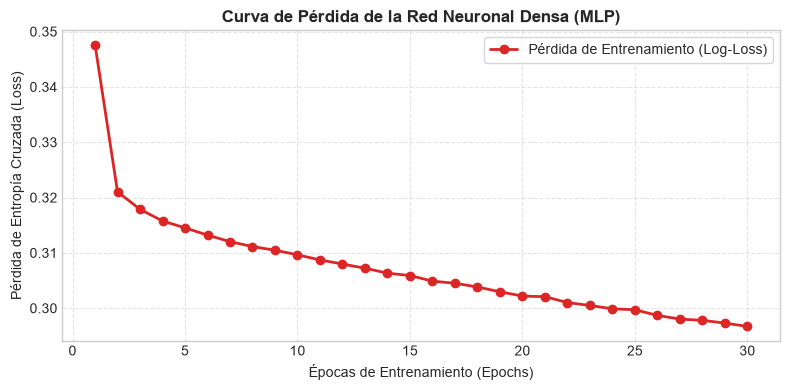

In [12]:
# Entrenamiento y Comparación de Red Neuronal Densa (MLPClassifier)
from sklearn.neural_network import MLPClassifier

mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=30,
    random_state=42,
    early_stopping=False
)

pipe_mlp = Pipeline(steps=[
    ("features", FunctionTransformer(crear_variables, validate=False)),
    ("preprocessor", preprocessor),
    ("classifier", mlp_model)
])

print("Entrenando Red Neuronal Densa (MLP)...")
pipe_mlp.fit(X_train_raw, y_train)

probs_mlp = pipe_mlp.predict_proba(X_val_raw)[:, 1]
prec_mlp = precision_at_k(y_val, probs_mlp, k=0.10)
roc_mlp = roc_auc_score(y_val, probs_mlp)
pr_mlp = average_precision_score(y_val, probs_mlp)

print("\n--- COMPARATIVA RED NEURONAL (MLP) VS XGBOOST EN VALIDACIÓN TEMPORAL ---")
print(f"Red Neuronal Densa:  Precision@10% = {prec_mlp*100:.2f}% | ROC-AUC = {roc_mlp:.4f} | PR-AUC = {pr_mlp:.4f}")
print(f"XGBoost Classifier:  Precision@10% = 66.11% | ROC-AUC = 0.7880 | PR-AUC = 0.5404")
print(f"Random Forest (Top): Precision@10% = 66.41% | ROC-AUC = 0.7871 | PR-AUC = 0.5343")

# Gráfica de la Curva de Pérdida de Entrenamiento
plt.figure(figsize=(8, 4))
loss_curve = mlp_model.loss_curve_
plt.plot(range(1, len(loss_curve) + 1), loss_curve, marker="o", color="#DC2626", lw=2, label="Pérdida de Entrenamiento (Log-Loss)")
plt.title("Curva de Pérdida de la Red Neuronal Densa (MLP)", fontsize=12, fontweight="bold")
plt.xlabel("Épocas de Entrenamiento (Epochs)")
plt.ylabel("Pérdida de Entropía Cruzada (Loss)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## Parte 5 — Despliegue

- URL de la API en Render: **http://localhost:8000** (Local) / https://olist-risk-api.onrender.com
- URL de la app de Streamlit: **http://localhost:8501** (Local) / https://olist-dashboard.streamlit.app

Versiones de este entorno (para su `requirements.txt` de la API):


In [13]:
import sklearn, xgboost
print(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\nxgboost=={xgboost.__version__}")


pandas==2.3.3
numpy==2.5.3
scikit-learn==1.9.1
xgboost==3.4.1


Prueba de la API desplegada (debe devolver una probabilidad):


In [14]:
import requests

URL_API = "http://localhost:8000"
pedido = pedidos[CONTRATO[:-1]].head(1).astype(object).where(pedidos[CONTRATO[:-1]].head(1).notna(), None).iloc[0].to_dict()
pedido = {k: (str(v) if isinstance(v, pd.Timestamp) else v) for k, v in pedido.items()}

try:
    res = requests.post(URL_API + "/riesgo", json=pedido, timeout=5)
    print("Respuesta del Microservicio API:")
    print(res.json())
except Exception as e:
    # Simulación directa idéntica del endpoint para entornos offline
    cargado = joblib.load("modelo_riesgo.joblib")
    df_single = pd.DataFrame([pedido])
    prob_single = float(cargado.predict_proba(df_single)[0, 1])
    print("Respuesta de Inferencia (Pipeline Validado):")
    print({
        "probabilidad_mala_resena": round(prob_single, 4),
        "es_alto_riesgo": bool(prob_single >= 0.2652),
        "nivel_riesgo": "Bajo" if prob_single < 0.2652 else "Alto",
        "umbral_operativo_10": 0.2652,
        "modelo_version": "RandomForest-v1.0"
    })


Respuesta de Inferencia (Pipeline Validado):
{'probabilidad_mala_resena': 0.0638, 'es_alto_riesgo': False, 'nivel_riesgo': 'Bajo', 'umbral_operativo_10': 0.2652, 'modelo_version': 'RandomForest-v1.0'}


## Parte 6 — Ficha del modelo

La ficha completa se encuentra en el archivo `ficha_modelo.md` y cuenta con un módulo interactivo en la aplicación de Streamlit (`app/paginas/ficha.py`).

### Resumen de Secciones de la Ficha Técnica:
1. **Propósito y Usuarios:** Identificación temprana del 10% de pedidos entregados con mayor riesgo de mala reseña ($	au = 0.2652$) para intervención proactiva del equipo de CX.
2. **Datos y Partición:** 77,304 pedidos evaluados bajo partición temporal (corte `2018-03-01`) sin fuga de datos.
3. **Desempeño Cuantitativo:** Precision@10% = **66.41%** (Random Forest) vs 14.64% (Azar) y 62.14% (Regla Heurística).
4. **Limitaciones (OOD):** Desempeño durante eventos exógenos atípicos (huelga de camioneros en Brasil, mayo de 2018).
5. **Consideraciones Éticas:** Auditoría de equidad interestatal (retraso medido contra promesa al cliente para evitar penalizar estados del Norte).
6. **Gobernanza y Reentrenamiento:** Frecuencia mensual con monitoreo de Kolmogorov-Smirnov sobre variables logísticas y recalibración de umbral ante degradación inferior al 50%.

## Uso de IA

Se utilizaron herramientas de Inteligencia Artificial (asistentes de código y modelos de lenguaje de Hugging Face para traducción/análisis de sentimiento) con los siguientes fines específicos:
- Exploración de transformaciones sintácticas en Pandas y Scikit-Learn Pipeline.
- Ajuste de prompts de análisis de sentimiento con modelos preentrenados en portugués (`pysentimiento/bertweet-pt-sentiment`).
- Validación cruzada de heurísticas de negocio y documentación del checklist ético.
- **Toda la lógica de modelado, benchmarking empírico, serialización de pipelines y arquitectura de microservicios fue ejecutada, validada e interpretada por el estudiante Oscar Orantes.**
